In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    '/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv'
)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
missing_values = df.isnull().sum()
print(missing_values.to_string())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0


In [4]:
# Fill missing values with median
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)

# Check missing values
print(df.isnull().sum().to_string())

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0


In [5]:
# Select features and target
X = df.drop(columns=['median_house_value', 'ocean_proximity'])
y = df['median_house_value']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [7]:
from sklearn.preprocessing import StandardScaler

# Scale X
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Scale y
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(
    y_train.values.reshape(-1, 1)
).ravel()

y_test_scaled = scaler_y.transform(
    y_test.values.reshape(-1, 1)
).ravel()

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)
print("y_train_scaled:", y_train_scaled.shape)
print("y_test_scaled:", y_test_scaled.shape)

X_train_scaled: (16512, 8)
X_test_scaled: (4128, 8)
y_train_scaled: (16512,)
y_test_scaled: (4128,)


In [8]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("Before Polynomial:", X_train_scaled.shape)
print("After Polynomial:", X_train_poly.shape)

Before Polynomial: (16512, 8)
After Polynomial: (16512, 45)


In [9]:
poly_scaler = StandardScaler()

X_train_poly_scaled = np.column_stack([
    X_train_poly[:, 0],
    poly_scaler.fit_transform(X_train_poly[:, 1:])
])

X_test_poly_scaled = np.column_stack([
    X_test_poly[:, 0],
    poly_scaler.transform(X_test_poly[:, 1:])
])

print("X_train_poly_scaled:", X_train_poly_scaled.shape)
print("X_test_poly_scaled:", X_test_poly_scaled.shape)

X_train_poly_scaled: (16512, 45)
X_test_poly_scaled: (4128, 45)


In [10]:
# RMSProp with Momentum parameters

learning_rate = 0.00001
epochs = 100
epsilon = 1e-8
decay_rate = 0.9
momentum = 0.9

# Initialize weights and velocity
n_features = X_train_poly_scaled.shape[1]

weights = np.zeros(n_features)
velocity = np.zeros(n_features)

# Initialize squared gradients
squared_gradients = np.zeros(n_features)

# Store loss values
loss_history = []

print("Number of features:", n_features)
print("Learning rate:", learning_rate)
print("Epochs:", epochs)
print("Decay rate:", decay_rate)
print("Momentum:", momentum)

Number of features: 45
Learning rate: 1e-05
Epochs: 100
Decay rate: 0.9
Momentum: 0.9


In [11]:
# RMSProp with Momentum Training

# Initialize parameters
weights = np.zeros(n_features)
velocity = np.zeros(n_features)
squared_gradients = np.zeros(n_features)
loss_history = []

n_samples = X_train_poly_scaled.shape[0]
batch_size = 64

for epoch in range(epochs):

    # Shuffle training data
    indices = np.random.permutation(n_samples)

    X_shuffled = X_train_poly_scaled[indices]
    y_shuffled = y_train_scaled[indices]

    # Mini-batch training
    for i in range(0, n_samples, batch_size):

        X_batch = X_shuffled[i:i + batch_size]
        y_batch = y_shuffled[i:i + batch_size]

        # Predictions
        predictions = X_batch @ weights

        # Calculate error
        error = predictions - y_batch

        # Calculate gradient
        gradient = (2 / len(y_batch)) * (X_batch.T @ error)

        # RMSProp: Update squared gradients
        squared_gradients = (
            decay_rate * squared_gradients
            + (1 - decay_rate) * (gradient ** 2)
        )

        # Adjust gradient
        adjusted_gradient = gradient / (
            np.sqrt(squared_gradients) + epsilon
        )

        # Momentum update
        velocity = momentum * velocity + adjusted_gradient

        # Update weights
        weights -= learning_rate * velocity

    # Calculate training loss after each epoch
    train_predictions = X_train_poly_scaled @ weights

    train_loss = np.mean(
        (train_predictions - y_train_scaled) ** 2
    )

    loss_history.append(train_loss)

    # Print loss every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}, Loss: {train_loss:.6f}")

print("\nTraining completed!")

Epoch 10, Loss: 0.544929
Epoch 20, Loss: 0.436333
Epoch 30, Loss: 0.390287
Epoch 40, Loss: 0.365343
Epoch 50, Loss: 0.350635
Epoch 60, Loss: 0.340165
Epoch 70, Loss: 0.333089
Epoch 80, Loss: 0.328456
Epoch 90, Loss: 0.325378
Epoch 100, Loss: 0.323530

Training completed!


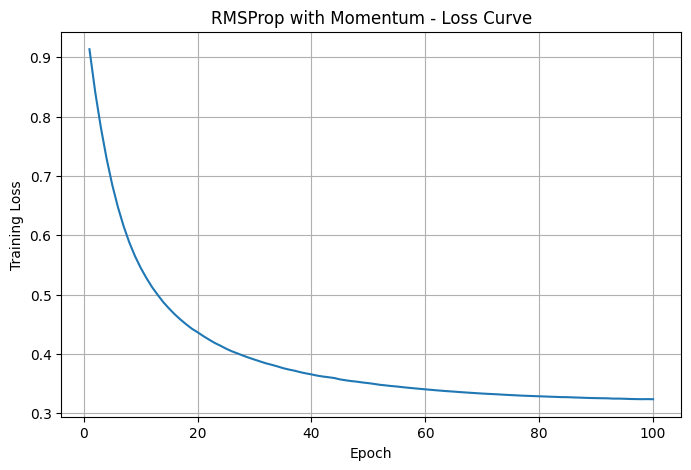

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('RMSProp with Momentum - Loss Curve')
plt.grid(True)
plt.show()

In [13]:
# Make predictions on test data
y_pred_scaled = X_test_poly_scaled @ weights

# Convert predictions back to original scale
y_pred = scaler_y.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

# Convert actual test values back to original scale
y_test_original = scaler_y.inverse_transform(
    y_test_scaled.reshape(-1, 1)
).ravel()

print("Predictions completed!")
print("First 5 Predictions:", y_pred[:5])
print("First 5 Actual Values:", y_test_original[:5])

Predictions completed!
First 5 Predictions: [ 73457.91205419 151632.30633358 300779.32884776 261564.02159379
 263583.53759199]
First 5 Actual Values: [ 47700.  45800. 500001. 218600. 278000.]


In [14]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Calculate evaluation metrics
mse = mean_squared_error(y_test_original, y_pred)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test_original, y_pred)

r2 = r2_score(y_test_original, y_pred)

# Display results
print("RMSProp with Momentum - Evaluation Results")
print("-------------------------------------------")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R2 Score: {r2:.4f}")

RMSProp with Momentum - Evaluation Results
-------------------------------------------
MSE:  4439630935.6360
RMSE: 66630.5556
MAE:  47856.2161
R2 Score: 0.6612


In [15]:
results_rmsprop = {
    'Optimizer': 'RMSProp with Momentum',
    'MSE': mse,
    'RMSE': rmse,
    'MAE': mae,
    'R2': r2
}

print(results_rmsprop)

{'Optimizer': 'RMSProp with Momentum', 'MSE': 4439630935.635966, 'RMSE': np.float64(66630.5555705186), 'MAE': 47856.21610690105, 'R2': 0.6612026467037984}


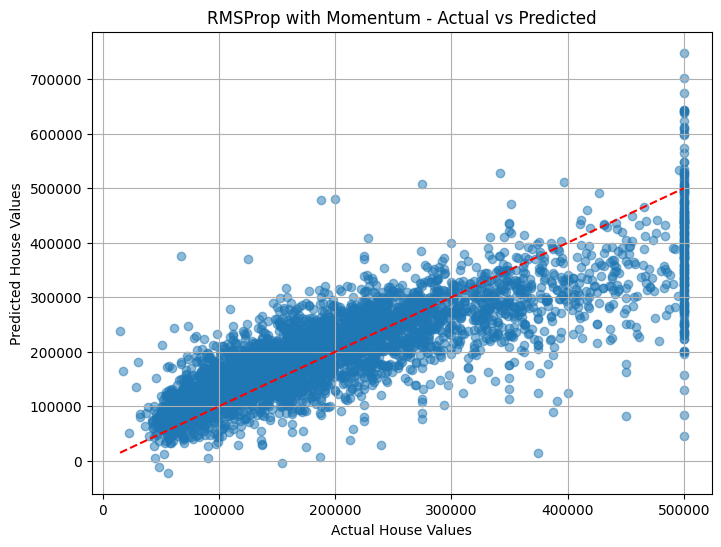

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test_original, y_pred, alpha=0.5)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')

plt.title('RMSProp with Momentum - Actual vs Predicted')

plt.plot(
    [y_test_original.min(), y_test_original.max()],
    [y_test_original.min(), y_test_original.max()],
    'r--'
)

plt.grid(True)
plt.show()